In [70]:
import psycopg2
import pandas as pd
import re 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

conn = psycopg2.connect(
    dbname="results",
    user="tmarmay",
    password="tmarmay",
    host="localhost",
    port=5432
)

query = "SELECT * FROM run_results;"
df = pd.read_sql(query, conn)
conn.close()

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_C(text):
        match = re.search(r'C(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_V(text):
        match = re.search(r'V(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["c"] = df["experiment_id"].apply(extract_C)
    df["v"] = df["experiment_id"].apply(extract_V)
    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = (2*c*v*n) + (3*(n**2)*v) + (2*v*c) + v
    return df


df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="nn_understanding"))
df = df[df['solver'] == 'NearestNeighbor']

/tmp/ipykernel_27229/2320450431.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


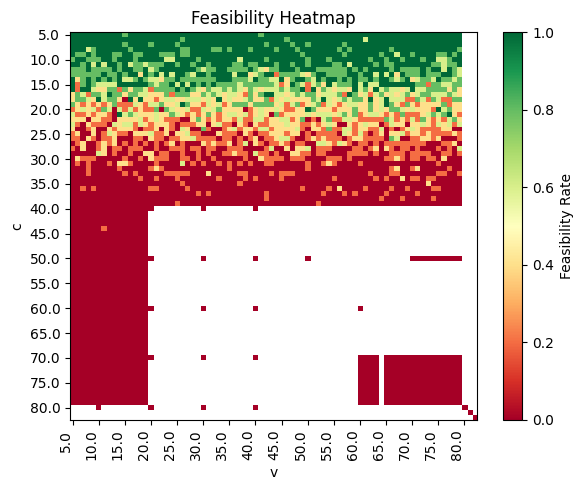

In [71]:
import numpy as np
import matplotlib.pyplot as plt

def heatmap_feasibility(df):

    summary = (
        df
        .groupby(["c", "v"])["feasible"]
        .mean()
        .reset_index()
    )

    if len(summary) == 0:
        return

    pivot = summary.pivot(
        index="c",
        columns="v",
        values="feasible"
    )

    all_c = np.sort(df["c"].unique())
    all_v = np.sort(df["v"].unique())

    pivot = pivot.reindex(index=all_c, columns=all_v)

    plt.figure(figsize=(6, 5))

    im = plt.imshow(
        pivot,
        aspect="auto",
        cmap="RdYlGn",
        vmin=0,
        vmax=1
    )

    plt.colorbar(im, label="Feasibility Rate")

    step = 5

    plt.xticks(
        range(0, len(pivot.columns), step),
        pivot.columns[::step],
        rotation=90,
        ha="right"
    )

    plt.yticks(
        range(0, len(pivot.index), step),
        pivot.index[::step]
    )
    plt.xlabel("v")
    plt.ylabel("c")
    plt.title(f"Feasibility Heatmap")
    plt.tight_layout()

    plt.show()
heatmap_feasibility(df)

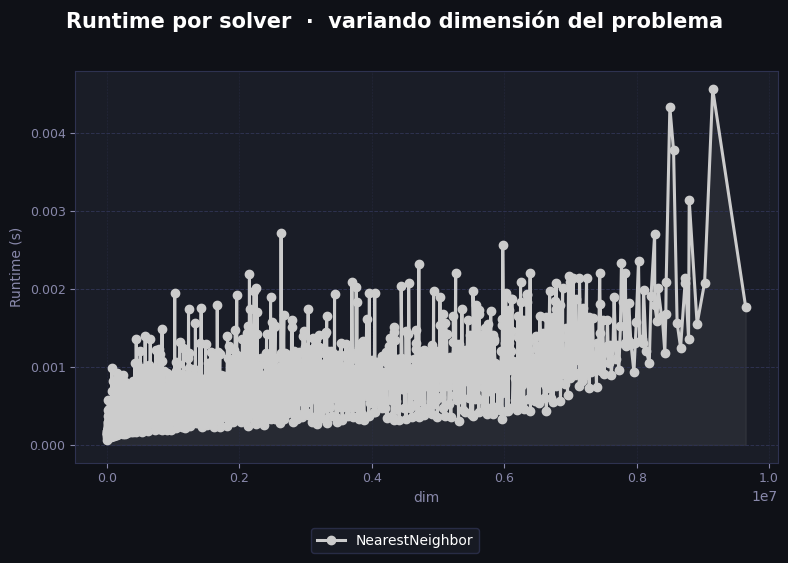

In [72]:
def plot_runtime_by_dim(df: pd.DataFrame, solver_colors: dict = {}):
    solvers = df["solver"].unique()

    fig, ax = plt.subplots(figsize=(8, 5))
    fig.patch.set_facecolor("#0F1117")
    ax.set_facecolor("#1A1D27")
    fig.suptitle(
        "Runtime por solver  ·  variando dimensión del problema",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    for solver in solvers:
        color = solver_colors.get(solver, "#CCCCCC")
        s = (
            df[df["solver"] == solver]
            .groupby("dim")["runtime"]
            .mean()
            .reset_index()
            .sort_values("dim")
        )
        if s.empty:
            continue
        ax.plot(
            s["dim"], s["runtime"],
            marker="o", linewidth=2.2, markersize=6,
            color=color, label=solver,
        )
        ax.fill_between(s["dim"], s["runtime"], alpha=0.08, color=color)

    for spine in ax.spines.values():
        spine.set_edgecolor("#2E3250")
    ax.tick_params(colors="#8888AA", labelsize=9)
    ax.set_xlabel("dim", color="#8888AA", fontsize=10)
    ax.set_ylabel("Runtime (s)", color="#8888AA", fontsize=10)
    ax.xaxis.set_major_locator(ticker.AutoLocator())
    ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
    ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=len(solvers),
        facecolor="#1A1D27", edgecolor="#2E3250",
        labelcolor="white", fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()

plot_runtime_by_dim(df[df['feasible']])

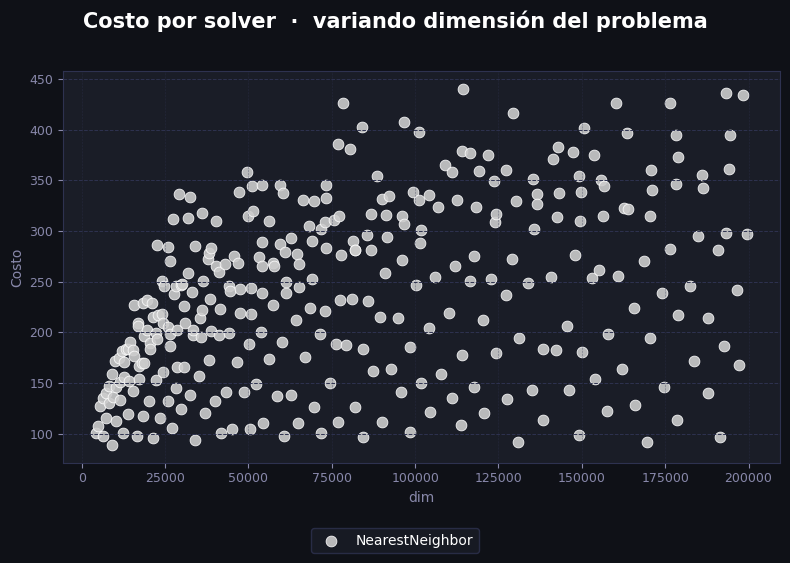

In [73]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

def plot_cost_by_dim(df: pd.DataFrame, solver_colors: dict = {}):
    solvers = df["solver"].unique()

    fig, ax = plt.subplots(figsize=(8, 5))
    fig.patch.set_facecolor("#0F1117")
    ax.set_facecolor("#1A1D27")
    fig.suptitle(
        "Costo por solver  ·  variando dimensión del problema",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    for solver in solvers:
        color = solver_colors.get(solver, "#CCCCCC")

        s = (
            df[df["solver"] == solver]
            .groupby("dim")["cost"]
            .mean()
            .reset_index()
            .sort_values("dim")
        )

        if s.empty:
            continue

        ax.scatter(
            s["dim"],
            s["cost"],
            s=60,              # tamaño del punto
            color=color,
            edgecolors="white",
            linewidth=0.6,
            alpha=0.9,
            label=solver,
        )

    # Estética
    for spine in ax.spines.values():
        spine.set_edgecolor("#2E3250")

    ax.tick_params(colors="#8888AA", labelsize=9)
    ax.set_xlabel("dim", color="#8888AA", fontsize=10)
    ax.set_ylabel("Costo", color="#8888AA", fontsize=10)

    ax.xaxis.set_major_locator(ticker.AutoLocator())
    ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
    ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=len(solvers),
        facecolor="#1A1D27",
        edgecolor="#2E3250",
        labelcolor="white",
        fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()
plot_cost_by_dim(df[(df['feasible']) & (df['dim'] < 200000)])

In [74]:
good_costs = df[(df['cost'] < 100) & (df['feasible'])].shape[0] / df.shape[0]
print(f"el porcentaje de resultados que tuvieron costos parecidos a los otros solvers: {good_costs * 100}")

el porcentaje de resultados que tuvieron costos parecidos a los otros solvers: 1.5900649953574746
